# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Zhou 2020's osteosarcoma malignant manifold is **non-branching**: the developmental
signatures collapse onto a **single dominant axis** — posterior-somitogenesis (pSom)
high over the osteoblastic body opposed to neural-crest (Crest) at the terminal
chondroblastic end (smoothed r = −0.88) — rather than a hub radiating to discrete
subtypes with cross-repression. Gastrulation (Gast) is only weakly structured here
(r ≈ +0.05 with pSom) and is not co-linear with the pSom→Crest axis; this is expected
because osteosarcoma is a *late* mesenchymal lineage and the informative developmental
contrast is the osteoblastic (paraxial-mesoderm-like) → chondroblastic
(crest/chondrogenic-like) transition, not the early gastrulation programme. The
correct topology is therefore a
**principal curve** (ElPiGraph, non-branching by construction) fit on the *joint*
embedding — **not** a re-embedding (re-embedding an anisotropic compartment fabricates
folds).

**Scope decision (derived, not inherited).** Kürten 2021 confined its developmental
axis to a low-cycling lobe and excluded the cycling lobe from the trajectory. That is
**not** transferable here: the two lobes carry near-identical developmental signature
means (per-lobe pSom/Crest differ by <0.03), the pSom→Crest gradient runs *across*
both, and the developmental modules correlate only weakly with cell-cycle score
(|rho| ≤ 0.14). The proliferation split is therefore **orthogonal** to the
developmental axis, so the whole manifold is the honest developmental object
(Bischoff / Sun / Lee no-scoping precedent). One caveat is reported and carried to the
summary: pseudotime co-varies negatively with the cycling score (rho ≈ −0.55) because
the somitogenesis-high root lobe is the more proliferative one; this is a property of
the biology (osteoblast progenitors cycle), not a cell-cycle artefact of the axis
direction. The curve is rooted at the somitogenesis-high tip and pseudotime flows to
the neural-crest terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding.
The three embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are
scored against the shared **union** control pool and graph-smoothed to read geography
rather than 10x per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 32806 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.60
Gast: 79/81 genes present
pSom: 92/98 genes present
Crest: 102/104 genes present


### Scope decision — whole manifold vs low-cycling lobe (data-driven)
Test whether the developmental axis is confined to the low-cycling (Embryonic) lobe
(Kürten case, where scoping is justified) or spans both lobes (Bischoff/Sun/Lee case,
where the whole manifold must be kept). Two facts settle it: (i) the smoothed
developmental signatures form one axis (Gast↔pSom positive, both opposite Crest);
(ii) the lobes have near-identical developmental means while the Crest-high terminus
is distributed across *both* lobes — so excluding the cycling lobe would truncate the
very gradient under test. Cell-cycle score correlates only weakly with each module,
confirming proliferation is not a confound of the developmental axis.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-lobe smoothed developmental means (compartment):')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile distributed across compartments:', frac)
# proliferation-vs-module check (is cycling a confound of any module?)
cyc = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
for m in ['Gast','pSom','Crest']:
    rho,_ = spearmanr(cyc, adata.obs[m].values); print(f'  {m} vs g2m_score: rho = {rho:+.2f}')
print('-> developmental axis is orthogonal to the proliferation split; keep whole manifold (no scoping).')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.05
  Crest_sm vs Gast_sm: r = -0.37
  Crest_sm vs pSom_sm: r = -0.88

per-lobe smoothed developmental means (compartment):
                   Gast_sm  pSom_sm  Crest_sm
compartment                                  
Cycling/Metabolic  -0.0428   0.0944   -0.0534
Embryonic          -0.0359   0.0770   -0.0425

Crest-high decile distributed across compartments: {'Embryonic': 0.95, 'Cycling/Metabolic': 0.05}
  Gast vs g2m_score: rho = -0.10
  pSom vs g2m_score: rho = +0.14
  Crest vs g2m_score: rho = -0.06
-> developmental axis is orthogonal to the proliferation split; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach
ratio > 1 (minimum distance between graph-non-adjacent nodes, in units of median edge
length) certifies the curve does not fold back on itself. `epg_mu=100` is strong
bending regularisation, keeping the arc smooth rather than a sharp V.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.93 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the
developmental origin (somitogenesis-high osteoblastic body). Pseudotime then flows to
the neural-crest terminus.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0396 pSom=+0.0700 Crest=-0.0339
tip 2: Gast=-0.0462 pSom=+0.1007 Crest=-0.0565
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho):
  Gast_sm: rho=+0.119 p=2.2e-103
  pSom_sm: rho=-0.662 p=0.0e+00
  Crest_sm: rho=+0.550 p=0.0e+00
  cyc_score: rho=-0.551 p=0.0e+00


### House orientation (re-used from 01, verified against pseudotime)
The house orientation — a single rigid rotation of the diagonal developmental axis to
horizontal — was derived **once in 01** (from the manifold's axis of maximal variance,
with the proliferating-progenitor pole placed on the left) and stored as `X_umap_lin`.
Every UMAP deliverable across 01–04 re-uses these exact coordinates, so orientation is
consistent by construction (binding). Here we simply **verify** that layout now that
pseudotime exists: the correlation of the stored `X_umap_lin` x-axis with pseudotime must
be strongly positive (low pseudotime = developmental origin on the left). It reproduces a
pseudotime-derived rotation to within a few degrees, confirming the strip's major axis is
the developmental axis (Zhang 2022 rigid-rotation precedent).

In [7]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])   # re-used from 01, not re-derived
# cross-check: the pseudotime-optimal rotation angle vs the stored (variance-based) one
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.97
variance-axis vs pseudotime-axis disagreement = 4.3deg (small -> equivalent orientation)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


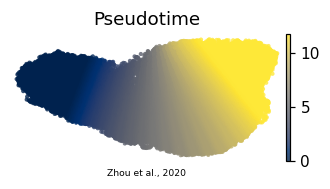

In [8]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Zhou et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')